# Per-station overview (Alaska)

One dashboard page per station, pulling together everything this project has
computed for it: NDVI/in-situ SM, De Zan coherence/closure-phase vs. in-situ
SM (NISAR and Sentinel-1 **merged into one panel each**, colored/labeled by
`<satellite> <track>`, each track with its **own regression line and
r-value** -- not just a pooled one like `Checks_alaska.ipynb`/
`Checks_alaska_S1.ipynb` use), and the estimated-vs-in-situ SM timeseries for
NISAR+SME2 and for S1. Local incidence angle and terrain slope/elevation are
printed as a text subtitle rather than their own panels -- each is a single
number (or a short one) per track/station, not a distribution worth its own
axes.

**Per-station, not fixed across stations**: axis ranges auto-scale to each
station's own data (a station with a narrow SM range gets a zoomed-in axis,
not one stretched to match every other station's), and track/orbit colors
are only kept consistent *within* one station's own set of panels -- a color
can repeat across different stations, just never twice within the same
station's page. Stations with no SM estimate at all (neither NISAR nor S1 --
e.g. no SoilGrids texture, or no usable coherence/closure data) are skipped
entirely, and a station with no NDVI coverage skips that one panel rather
than showing an empty axes.

**Depth: 5cm only**, all points, **no quality/fault filtering** on the
in-situ series (this project's `read_insitu` no longer does any).

**Figure size: 15x9 in (~10:6), one slide each** -- sized to drop straight
into a Google Slides deck without further cropping.

**Data sources** (all precomputed by other notebooks in this project -- this
notebook only reads and plots, no new computation except station terrain):
- In-situ SM: `ismn_data/alaska/station_data/{station}_ts_0.05.csv`
- NDVI: `nisar_data/alaska_HLS_ndvi/{station}_HLS_ndvi.csv`
- NISAR coherence/closure: `nisar_data/alaska_GSLC_coherence_closure/{station}_NISAR_GSLC_*.csv`
- Sentinel-1 coherence/closure: `S1_coherence_closure_alaska/{station}_orbit*_S1_*.csv`
- SME2: `SME2_data_alaska/sme2_cache.csv`
- NISAR/S1 SM estimates: `nisar_data/alaska_NISAR_SM_estimates.csv` / `S1_SM_estimates_alaska.csv`
  (written by the export cell at the end of `NISAR_SM_alaska.ipynb` /
  `S1_SM_alaska.ipynb` -- **re-run those two notebooks first** if you want
  this page to reflect a fresh inversion run)
- Station terrain (slope): computed here directly from Copernicus GLO-30,
  the same way `Earsel26_NISAR-main/util/nisar_station_timeseries.py`'s
  `compute_station_terrain` does for the GCOV backscatter pipeline -- no
  Earthdata credentials needed, just public DEM tiles.

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()
EARSEL_NOTEBOOKS = BASE / "Earsel26_NISAR-main" / "notebooks"
EARSEL_ROOT = EARSEL_NOTEBOOKS.parent
if str(EARSEL_ROOT) not in sys.path:
    sys.path.append(str(EARSEL_ROOT))

COH_CLOSURE_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_GSLC_coherence_closure"
NDVI_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_HLS_ndvi"
INSITU_DIR = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "station_data"
S1_COH_CLOSURE_DIR = BASE / "S1_coherence_closure_alaska"
SME2_CACHE_PATH = BASE / "SME2_data_alaska" / "sme2_cache.csv"
NISAR_SM_ESTIMATES_PATH = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_NISAR_SM_estimates.csv"
S1_SM_ESTIMATES_PATH = BASE / "S1_SM_estimates_alaska.csv"

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DEPTH_MAIN = 0.05
MAX_GAP_HOURS = 6
# Same safeguard Checks_alaska.ipynb/Checks_alaska_S1.ipynb use: a same-pass
# adjacent-frame pair/triplet leg can have a temporal baseline of seconds,
# which would otherwise show up as a near-zero-dSM point that's structurally
# guaranteed to look uninformative, not a real test of anything.
MIN_BASELINE_DAYS = 0.01


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Station list

In [2]:
require_globals("EARSEL_NOTEBOOKS")

stations_path = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "stations.geojson"
with open(stations_path) as f:
    stations_geojson = json.load(f)

stations = {
    feat["properties"]["station_val"]: (
        feat["geometry"]["coordinates"][1],  # lat
        feat["geometry"]["coordinates"][0],  # lon
    )
    for feat in stations_geojson["features"]
}
print(f"Loaded {len(stations)} stations")


Loaded 20 stations


## 2. Data readers

Every reader returns `None` (or an empty DataFrame) when a station has no
file for that source -- every plot function below handles that by simply
leaving its panel empty, not by raising.

In [3]:
require_globals("INSITU_DIR", "NDVI_DIR", "COH_CLOSURE_DIR", "S1_COH_CLOSURE_DIR")


def read_insitu(station, depth=DEPTH_MAIN):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))


def _sm_diff_pct(df, series, col_a, col_b):
    a = df[col_a].apply(lambda ts: interp_insitu_at(series, ts))
    b = df[col_b].apply(lambda ts: interp_insitu_at(series, ts))
    return (a - b).abs() * 100


def _sm_range_pct(df, series, cols):
    vals = pd.concat([df[c].apply(lambda ts: interp_insitu_at(series, ts)) for c in cols], axis=1)
    return (vals.max(axis=1, skipna=False) - vals.min(axis=1, skipna=False)) * 100


def read_ndvi(station):
    path = NDVI_DIR / f"{station}_HLS_ndvi.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["target_date"])
    df = df[df["n_valid_px"] > 0]
    if df.empty:
        return None
    return df.set_index("target_date")["ndvi_mean"].sort_index()


def read_nisar_coherence(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_coherence.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2"])
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_nisar_closure(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_closure_phase.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2", "date_3"])
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


def read_s1_coherence(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_coherence.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_s1_closure(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2", "date_3"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_closure_phase.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


## 3. SME2 and SM-estimate tables

In [4]:
sme2_df = (
    pd.read_csv(SME2_CACHE_PATH, parse_dates=["timestamp"])
    if SME2_CACHE_PATH.exists() else pd.DataFrame(columns=["station", "timestamp", "sm_pct"])
)
nisar_est_df = pd.read_csv(NISAR_SM_ESTIMATES_PATH, parse_dates=["date"])
s1_est_df = pd.read_csv(S1_SM_ESTIMATES_PATH, parse_dates=["date"])


def read_sme2(station):
    sub = sme2_df[sme2_df["station"] == station]
    if sub.empty:
        return None
    return sub.set_index("timestamp")["sm_pct"].sort_index()


def read_nisar_estimates(station, depth_label="5cm"):
    return nisar_est_df[(nisar_est_df["station"] == station) & (nisar_est_df["depth"] == depth_label)]


def read_s1_estimates(station, depth_label="5cm"):
    return s1_est_df[(s1_est_df["station"] == station) & (s1_est_df["depth"] == depth_label)]


print(f"SME2 cache: {sme2_df['station'].nunique()} station(s), {len(sme2_df)} row(s)")
print(f"NISAR SM estimates: {len(nisar_est_df)} row(s)")
print(f"S1 SM estimates: {len(s1_est_df)} row(s)")


SME2 cache: 7 station(s), 188 row(s)
NISAR SM estimates: 732 row(s)
S1 SM estimates: 224 row(s)


## 4. Station terrain (slope)

Reuses `Earsel26_NISAR-main/util/nisar_station_timeseries.py`'s own
`compute_station_terrain` -- a 3x3 Copernicus GLO-30 window per station,
Horn's-method slope/aspect, streamed from the public DEM bucket (no
Earthdata login needed, unlike the GCOV/GSLC pipeline itself).

In [5]:
require_globals("EARSEL_ROOT", "stations")

from util.nisar_station_timeseries import compute_station_terrain

station_dicts = [{"name": name, "lon": lon, "lat": lat} for name, (lat, lon) in stations.items()]
compute_station_terrain(station_dicts)
slope_by_station = {d["name"]: d["dem_slope_deg"] for d in station_dicts}
elevation_by_station = {d["name"]: d["dem_elevation_m"] for d in station_dicts}


Computing local terrain slope/aspect from Copernicus GLO-30 for each station...


Done. 18 unique DEM tiles used for 20 stations.
Slope range across stations: 0.51 - 9.41 deg (median 1.42 deg)


## 5. Stations to plot

Drops any station with no SM estimate at all (neither NISAR nor S1, at
5cm) -- there's nothing to show in half the page for these, and it's
usually an upstream data gap (e.g. missing SoilGrids texture, or no usable
coherence/closure data), not something this notebook can fix.

In [6]:
require_globals("stations", "read_nisar_estimates", "read_s1_estimates")

stations_to_plot = sorted(
    s for s in stations
    if not read_nisar_estimates(s).empty or not read_s1_estimates(s).empty
)
skipped = sorted(set(stations) - set(stations_to_plot))
print(f"{len(stations_to_plot)}/{len(stations)} station(s) have at least one 5cm SM estimate -- plotting those")
if skipped:
    print(f"Skipped (no NISAR or S1 estimate): {skipped}")


16/20 station(s) have at least one 5cm SM estimate -- plotting those
Skipped (no NISAR or S1 estimate): ['Aniak', 'MooseInc', 'Nenana', 'PrudhoeBay']


## 6. Per-station color map

One color per `(satellite, track)` pair actually present *at that station*
(built fresh inside the main loop below, not once globally) -- keeps colors
visually distinct within a station's own panels (a station rarely has more
than a handful of tracks total, so it never has to stretch far into a large
qualitative palette the way a single shared 24-track map would), at the cost
of the same color potentially meaning a different track on a different
station's page. `NISAR`/`S1` both figure into one map so the coherence and
closure-phase panels (Section 8, merged across sensors) never collide.

In [7]:
def build_station_color_map(nisar_tracks, s1_orbits):
    ids = [("NISAR", t) for t in sorted(nisar_tracks)] + [("S1", o) for o in sorted(s1_orbits)]
    n = len(ids)
    if n == 0:
        return {}
    colors = plt.cm.tab10(np.linspace(0, 1, 10))[:n] if n <= 10 else plt.cm.turbo(np.linspace(0, 1, n))
    return dict(zip(ids, colors))


## 7. Panel functions

One function per panel type. Nothing here sets a fixed axis range -- every
panel auto-scales to whatever that station's own data spans.

In [8]:
def plot_ndvi_insitu(ax, station):
    ax2 = ax.twinx()
    series = read_insitu(station)
    if series is not None:
        ax.plot(series.index, series.values * 100, color="black", linewidth=1, alpha=0.7, label="in-situ SM")
    ndvi = read_ndvi(station)
    if ndvi is not None:
        ax2.plot(ndvi.index, ndvi.values, color="tab:green", marker="o", markersize=3, linewidth=1, label="NDVI")
    ax.set_ylabel("SM (%)", color="black")
    ax2.set_ylabel("NDVI", color="tab:green")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    if h1 or h2:
        ax.legend(h1 + h2, l1 + l2, fontsize=6, loc="upper right")
    ax.set_title("NDVI & in-situ SM (5cm)", fontsize=9)
    ax.grid(True, alpha=0.3)


In [9]:
def plot_coherence_merged(ax, station, series, color_map):
    ax.set_xlabel("|SM diff| (%)")
    ax.set_ylabel("Coherence")
    ax.set_title("Coherence vs. |SM diff| (5cm)", fontsize=9)
    sources = [
        ("NISAR", read_nisar_coherence(station), "coherence_HH", "orbit_num"),
        ("S1", read_s1_coherence(station), "coherence_VV", "orbit"),
    ]
    for sensor, df_all, coh_col, track_col in sources:
        if df_all is None or series is None or df_all.empty:
            continue
        df = df_all.copy()
        df["dsm"] = _sm_diff_pct(df, series, "date_1", "date_2")
        valid = df[coh_col].notna() & df["dsm"].notna()
        df = df.loc[valid]
        for track, g in df.groupby(track_col):
            color = color_map.get((sensor, track), "gray")
            ax.scatter(g["dsm"], g[coh_col], color=color, s=18, zorder=3)
            if len(g) >= 2 and g["dsm"].std() > 0 and g[coh_col].std() > 0:
                x, y = g["dsm"].values, g[coh_col].values
                r = np.corrcoef(x, y)[0, 1]
                fit = np.polyfit(x, y, 1)
                xs = np.array([x.min(), x.max()])
                ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2,
                        label=f"{sensor} {track} (r={r:.2f})")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=5, loc="best", ncol=2)
    ax.grid(True, alpha=0.3)


In [10]:
def plot_closure_merged(ax, station, series, color_map):
    ax.set_xlabel("SM range across triplet (%)")
    ax.set_ylabel("|Closure phase| (rad)")
    ax.set_title("Closure phase vs. SM range (5cm)", fontsize=9)
    sources = [
        ("NISAR", read_nisar_closure(station), "closure_phase_HH", "orbit_num"),
        ("S1", read_s1_closure(station), "closure_phase_VV", "orbit"),
    ]
    for sensor, df_all, closure_col, track_col in sources:
        if df_all is None or series is None or df_all.empty:
            continue
        df = df_all.copy()
        df["sm_range"] = _sm_range_pct(df, series, ["date_1", "date_2", "date_3"])
        df["abs_closure"] = df[closure_col].abs()
        valid = df["abs_closure"].notna() & df["sm_range"].notna()
        df = df.loc[valid]
        for track, g in df.groupby(track_col):
            color = color_map.get((sensor, track), "gray")
            ax.scatter(g["sm_range"], g["abs_closure"], color=color, s=18, zorder=3)
            if len(g) >= 2 and g["sm_range"].std() > 0 and g["abs_closure"].std() > 0:
                x, y = g["sm_range"].values, g["abs_closure"].values
                r = np.corrcoef(x, y)[0, 1]
                fit = np.polyfit(x, y, 1)
                xs = np.array([x.min(), x.max()])
                ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2,
                        label=f"{sensor} {track} (r={r:.2f})")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=5, loc="best", ncol=2)
    ax.grid(True, alpha=0.3)


In [11]:
def _scatter_estimates(ax, est_df, id_col, sensor, color_map):
    for track_id, g in est_df.groupby(id_col):
        color = color_map.get((sensor, track_id), "gray")
        normal = g[~g["is_dry_anchor"]]
        anchor = g[g["is_dry_anchor"]]
        ax.scatter(normal["date"], normal["sm_pct"], color=color, s=22, marker="o", zorder=3)
        ax.scatter(anchor["date"], anchor["sm_pct"], color=color, s=110, marker="*",
                    edgecolor="black", linewidth=0.6, zorder=4)


def plot_nisar_estimate_timeseries(ax, station, color_map):
    ax.set_ylabel("SM (%)")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.set_title("SME2 / NISAR estimate / in-situ (5cm, points only, \u2605 = dry anchor)", fontsize=9)
    series = read_insitu(station)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=3, alpha=0.3, label="in-situ", zorder=1)
    sme2 = read_sme2(station)
    if sme2 is not None:
        ax.scatter(sme2.index, sme2.values, color="dimgray", marker="^", s=35, label="SME2", zorder=2)
    est = read_nisar_estimates(station)
    if not est.empty:
        _scatter_estimates(ax, est, "track", "NISAR", color_map)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=6, loc="upper right")
    ax.grid(True, alpha=0.3)


def plot_s1_estimate_timeseries(ax, station, color_map):
    ax.set_ylabel("SM (%)")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.set_title("S1 estimate / in-situ (5cm, points only, \u2605 = dry anchor)", fontsize=9)
    series = read_insitu(station)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=3, alpha=0.3, label="in-situ", zorder=1)
    est = read_s1_estimates(station)
    if not est.empty:
        _scatter_estimates(ax, est, "orbit", "S1", color_map)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=6, loc="upper right")
    ax.grid(True, alpha=0.3)


In [12]:
def incidence_summary_text(station):
    parts = []
    coh = read_nisar_coherence(station)
    if coh is not None and not coh.empty:
        vals = coh.groupby("orbit_num")["local_incidence_angle_deg"].mean()
        parts.append("NISAR " + ", ".join(f"{int(t)}={v:.0f}\u00b0" for t, v in vals.items()))
    s1coh = read_s1_coherence(station)
    if s1coh is not None and not s1coh.empty:
        vals = s1coh.groupby("orbit")["local_incidence_angle_deg"].mean()
        parts.append("S1 " + ", ".join(f"{int(t)}={v:.0f}\u00b0" for t, v in vals.items()))
    return "incidence angle: " + "; ".join(parts) if parts else ""


## 8. Per-station pages

Row 1: NDVI+in-situ, merged coherence, merged closure phase (3 panels when
NDVI exists, else just the two coherence/closure panels). Row 2: NISAR+SME2
estimate timeseries, S1 estimate timeseries (always 2 panels). A row with
only 2 panels is centered in the row's width, not left-aligned against an
empty third slot -- built on a 2x6 `GridSpec` so a 2-panel row can occupy
the centered columns 1:5 while a 3-panel row fills the whole 0:6. Station
slope/elevation and local incidence angle per track go in the title/subtitle
rather than their own panels.

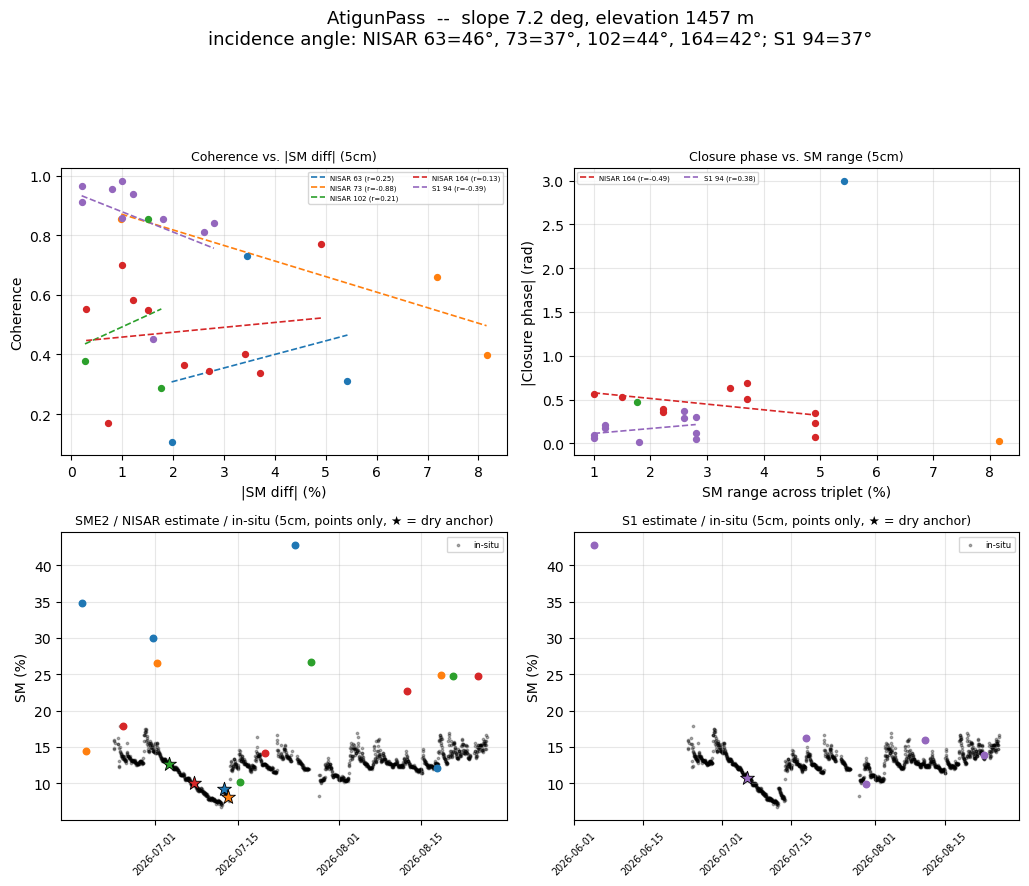

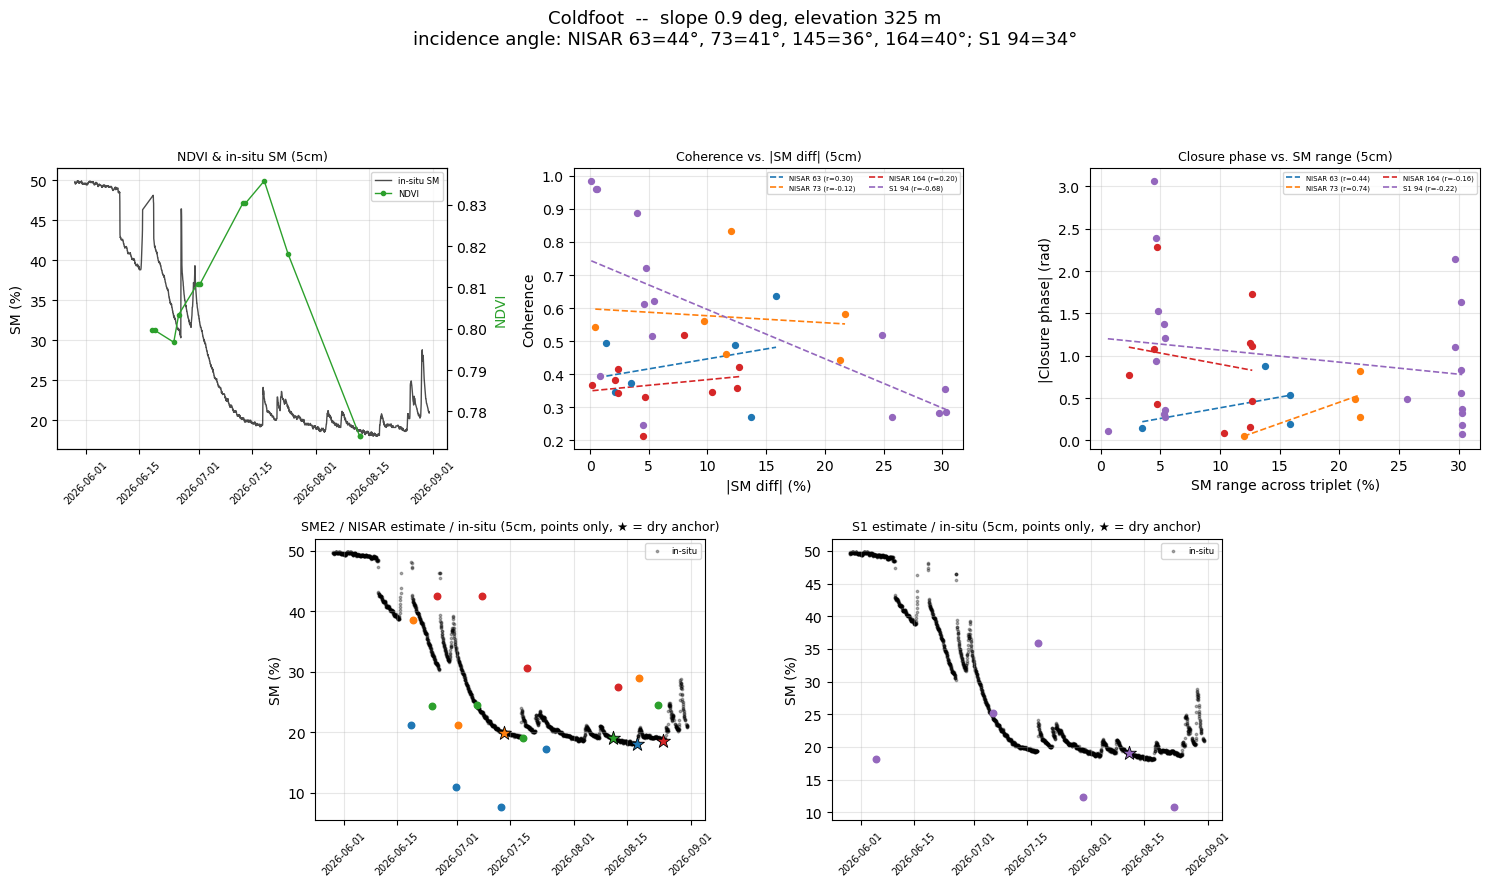

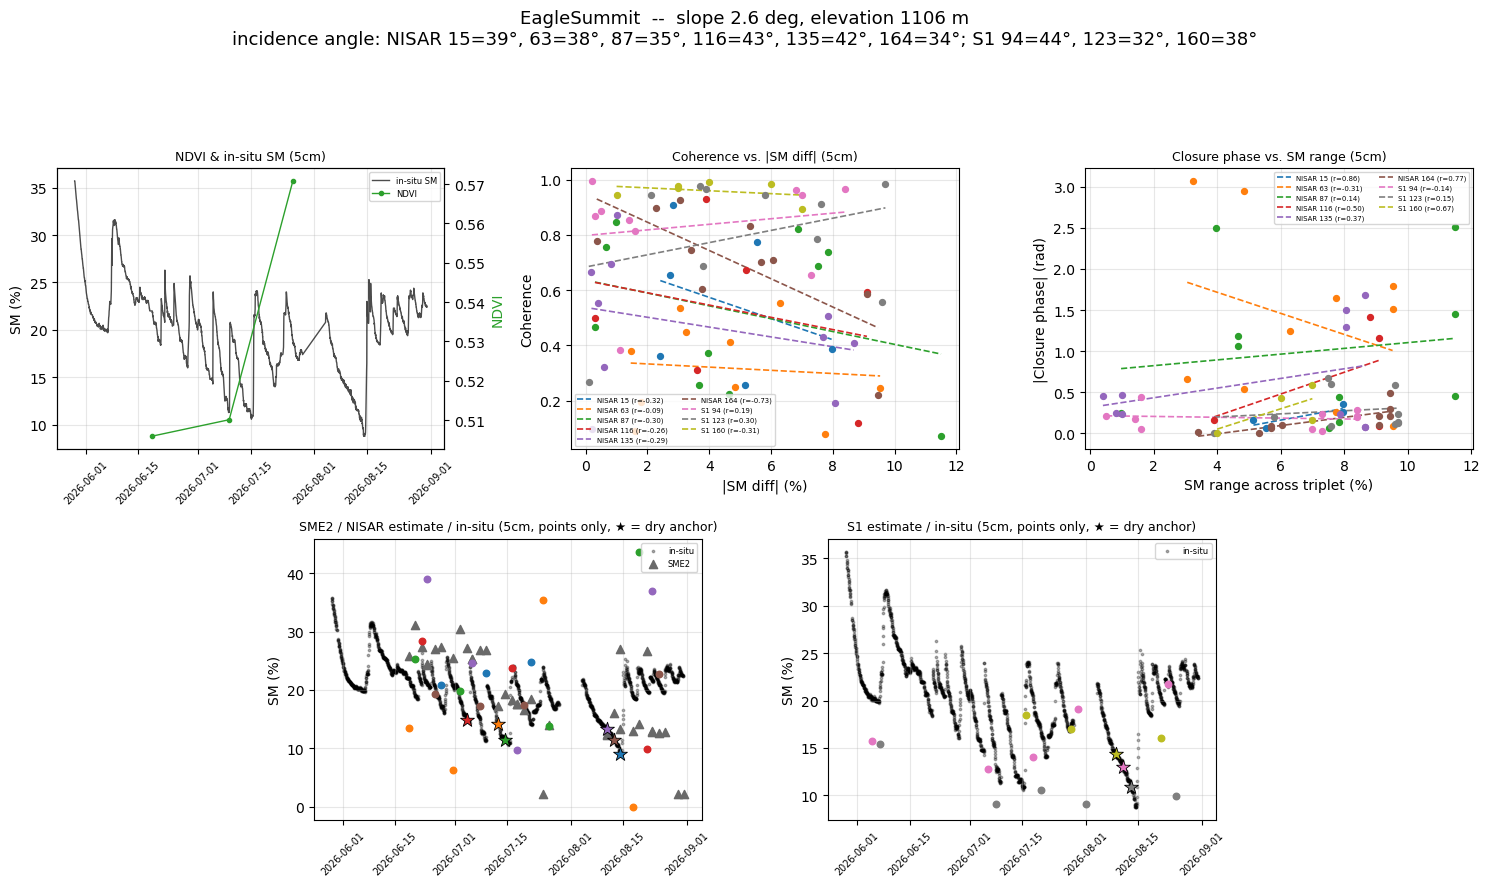

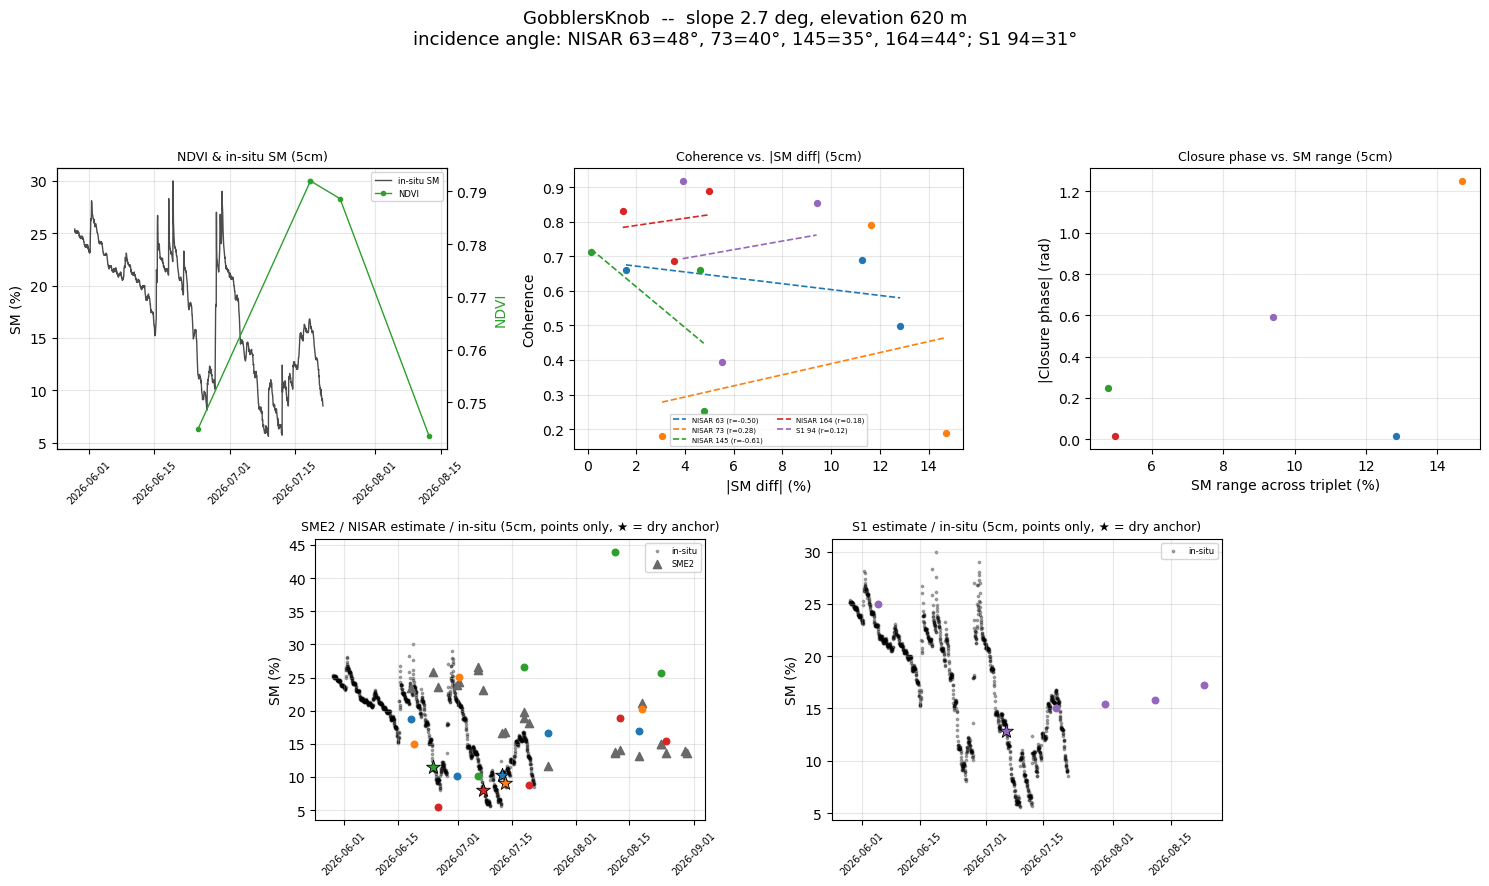

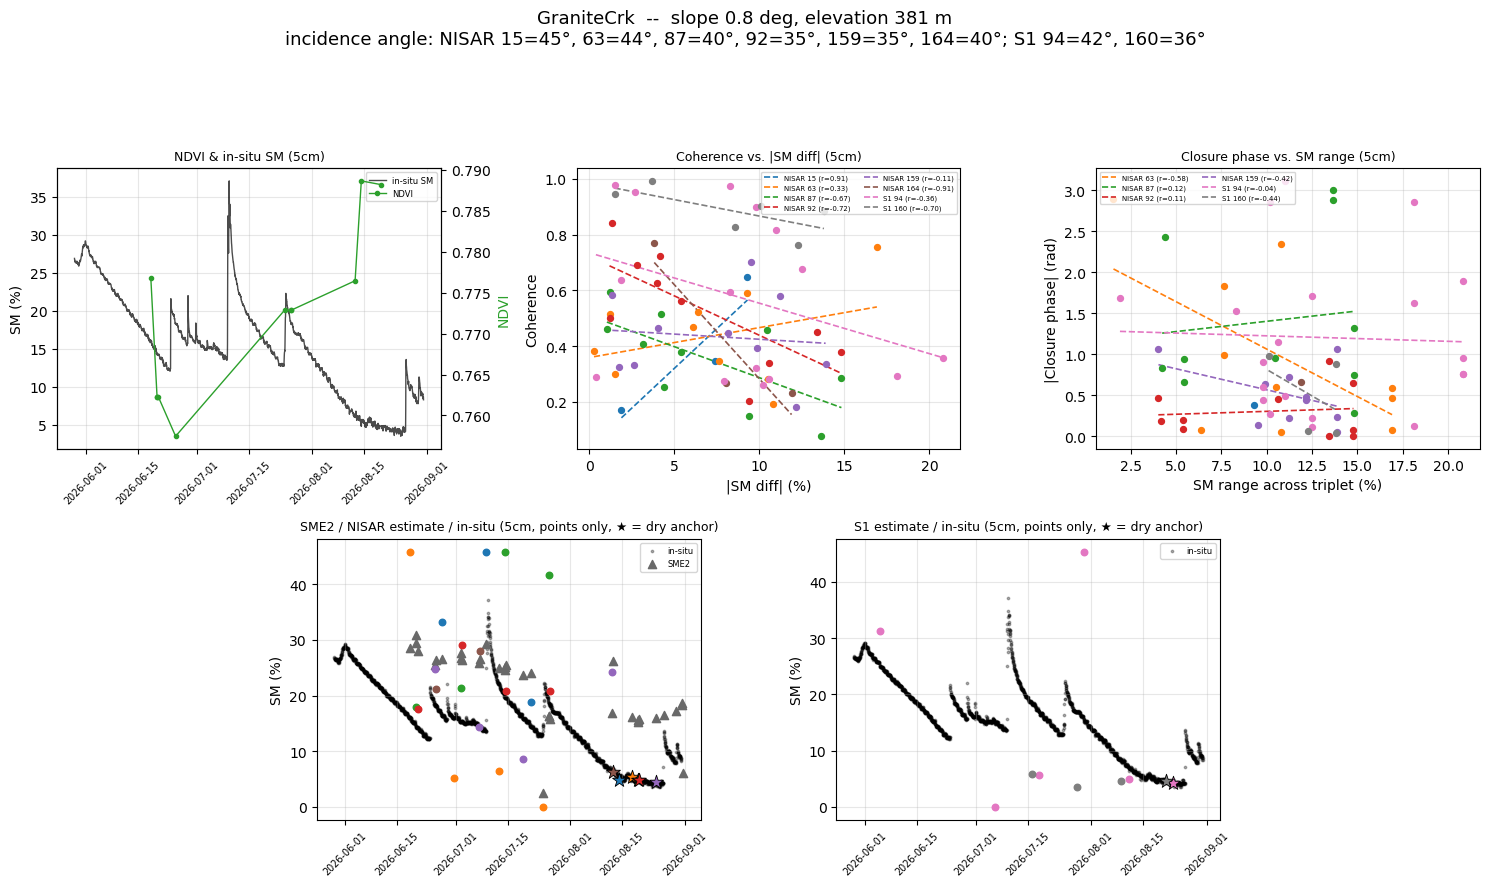

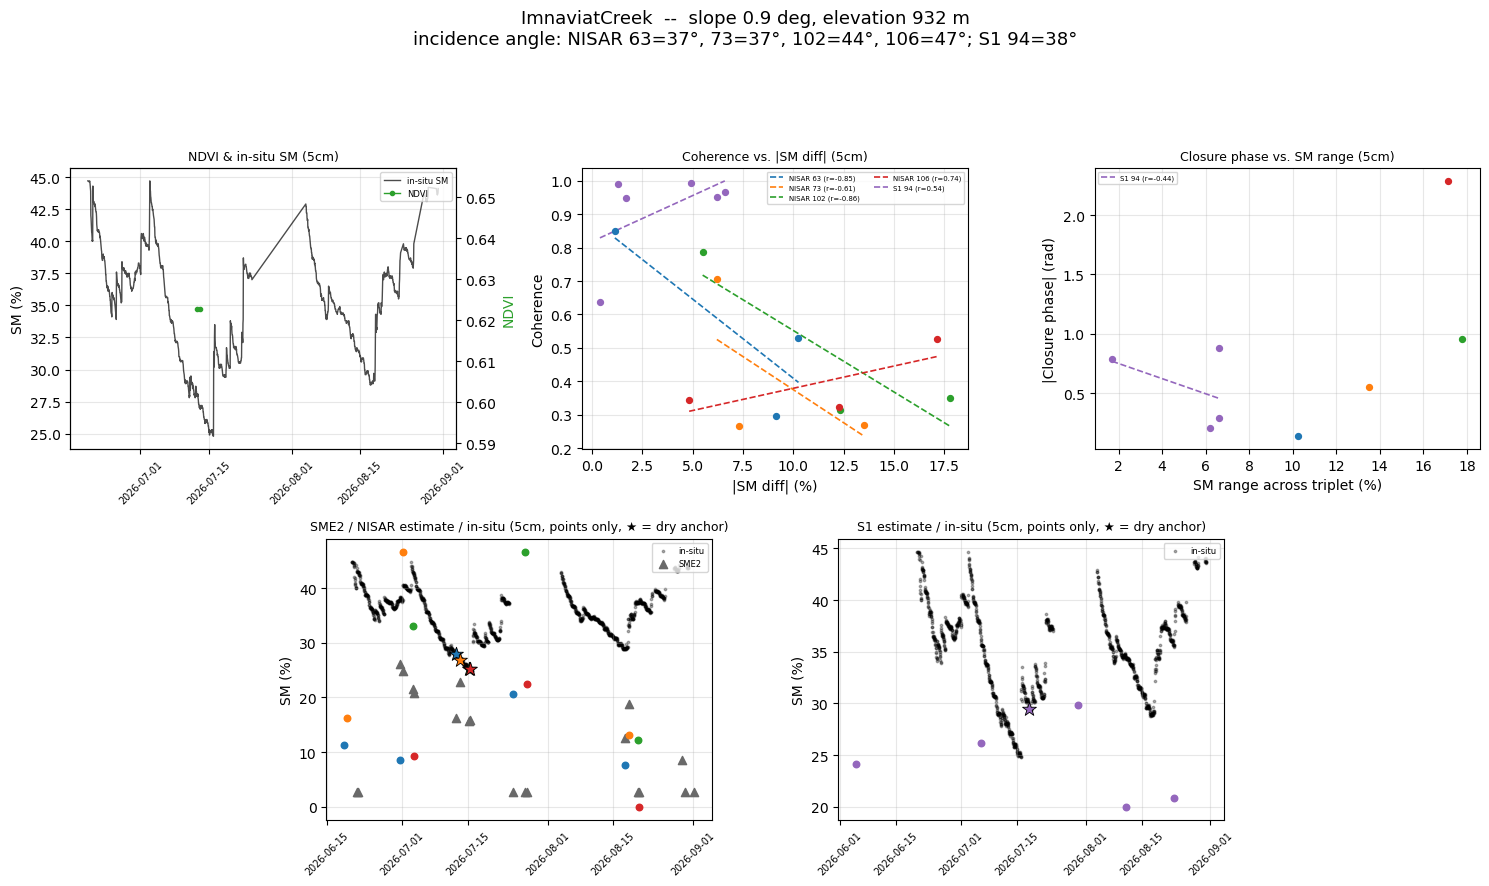

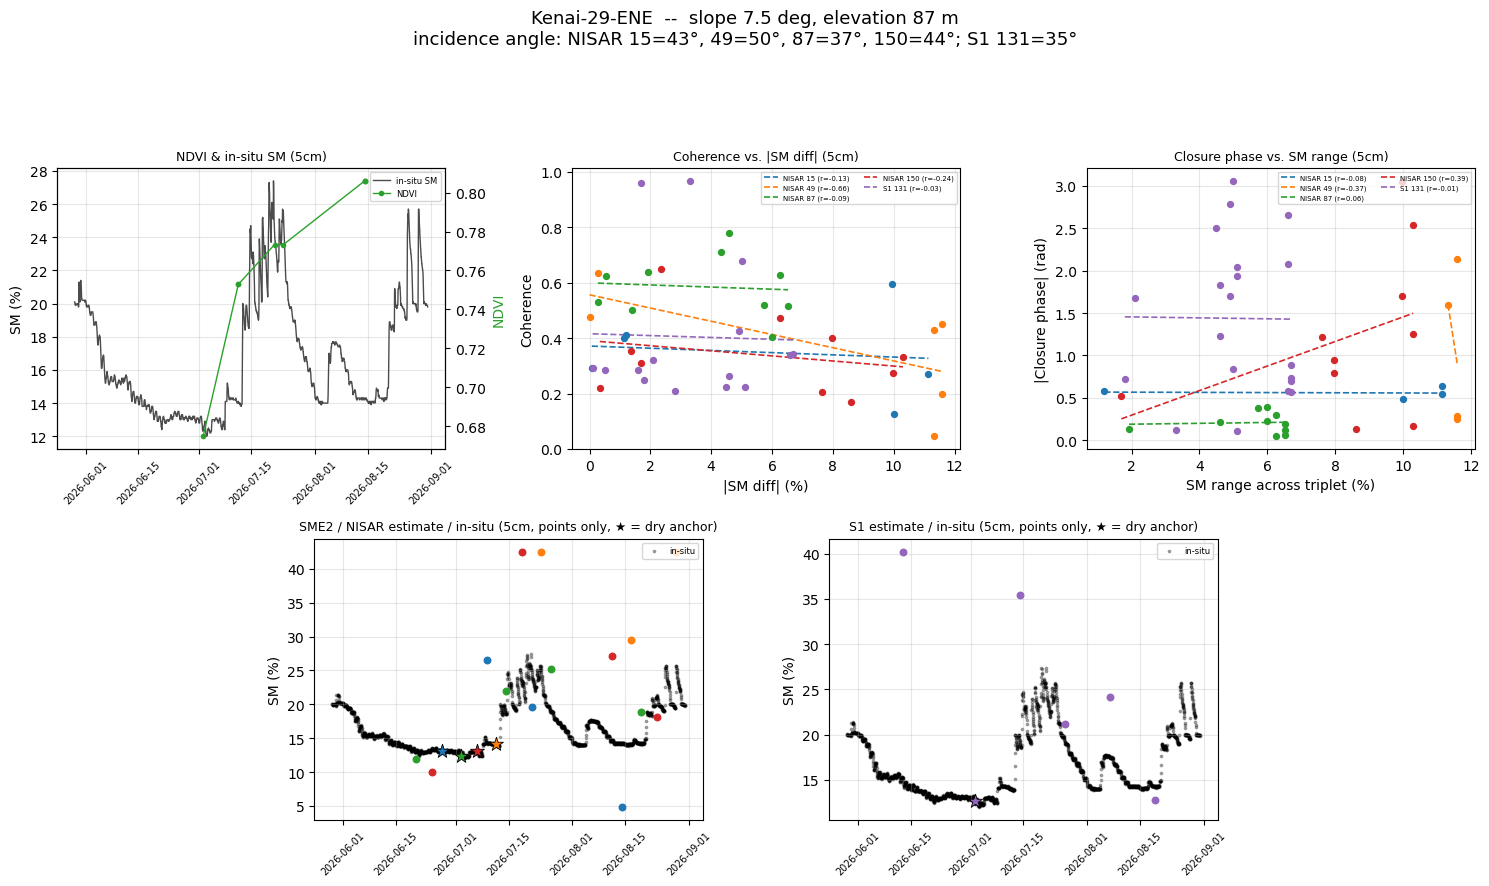

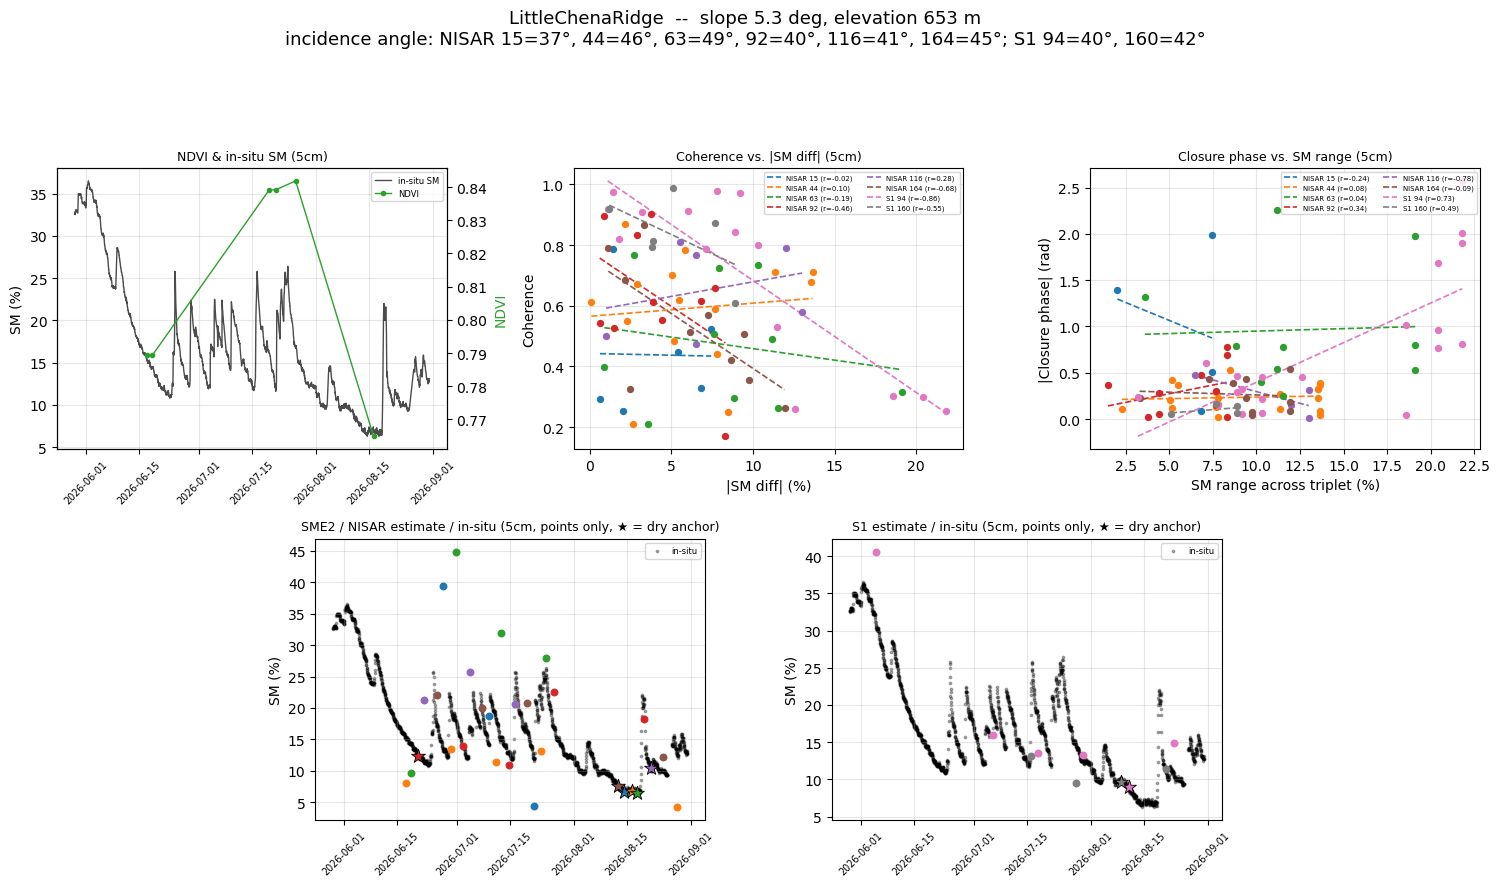

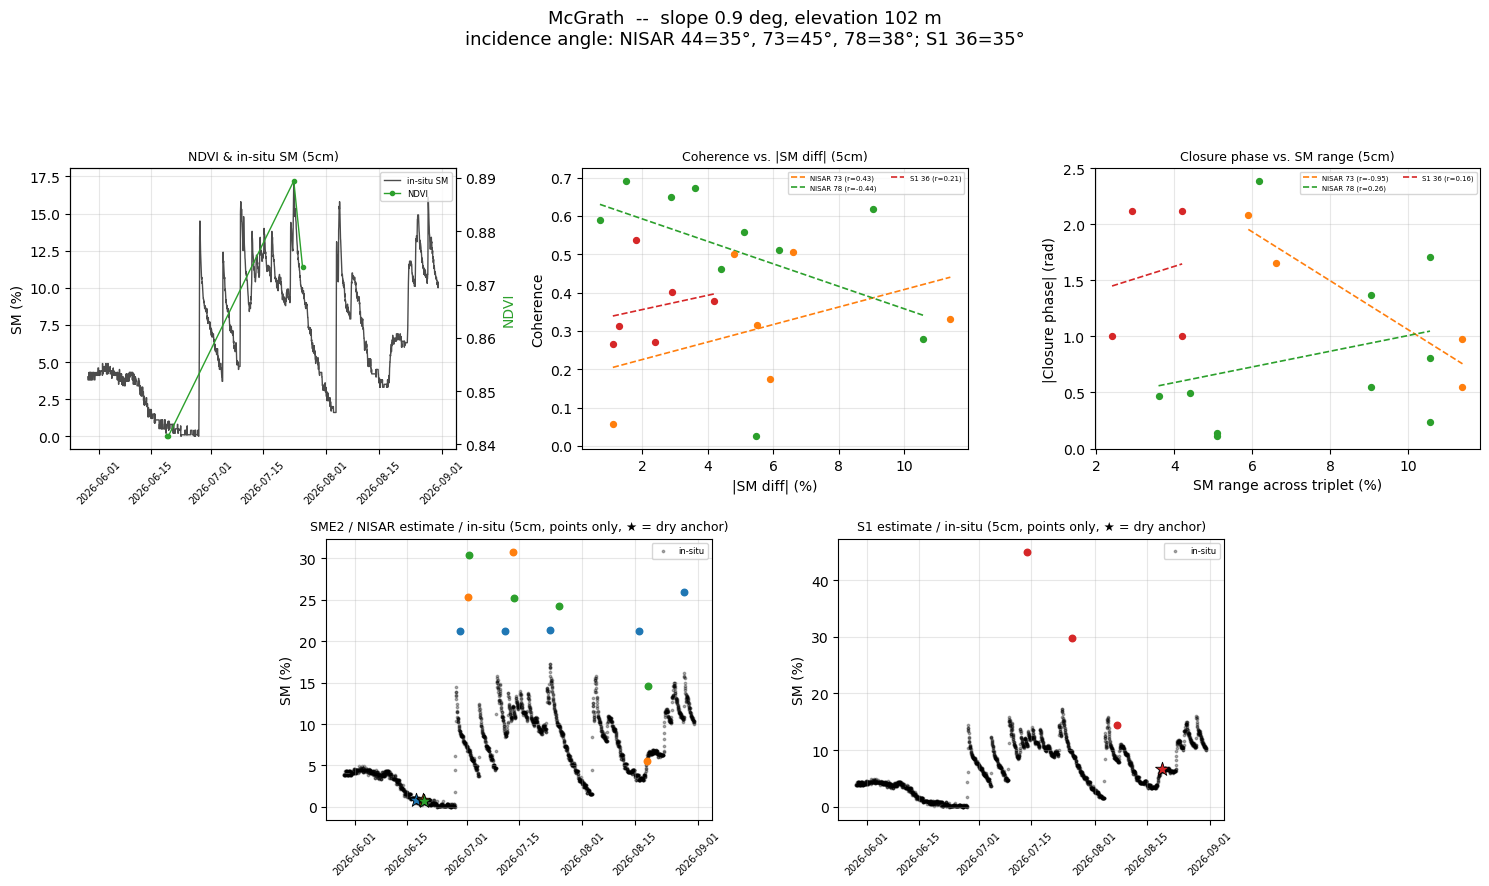

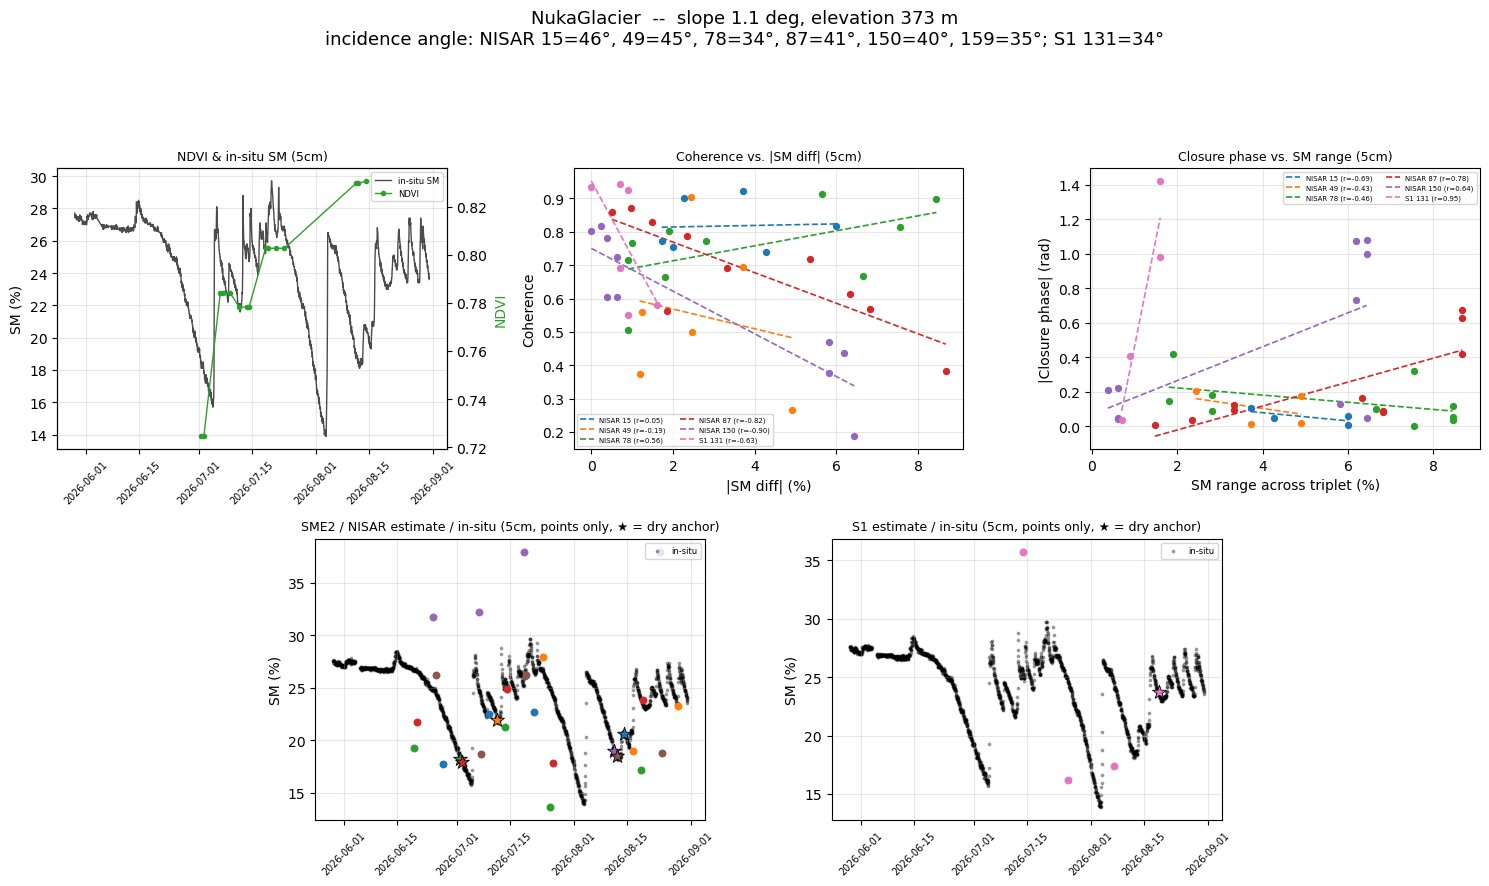

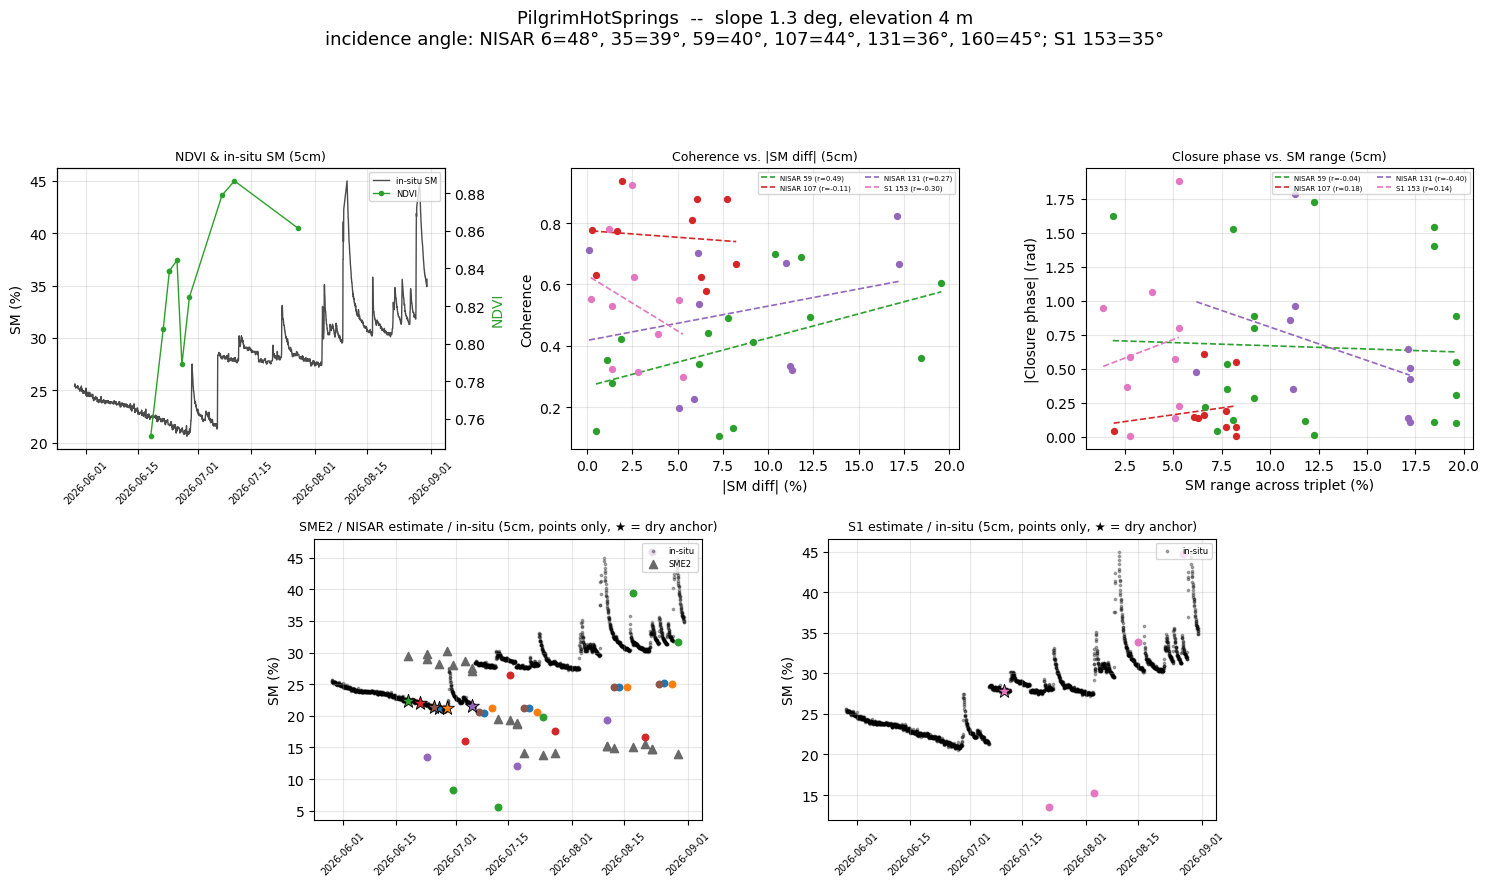

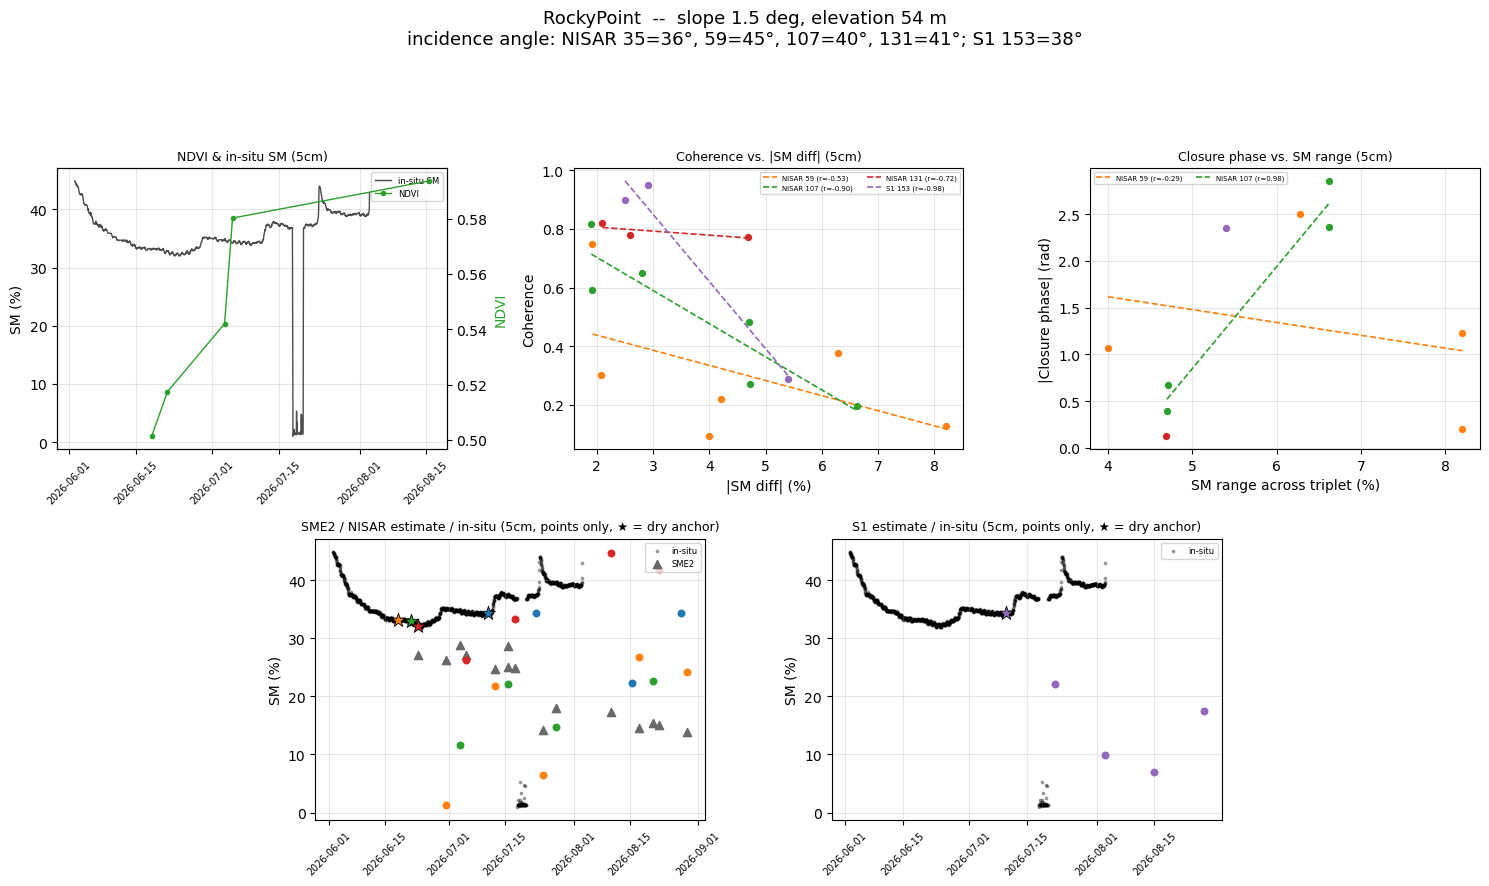

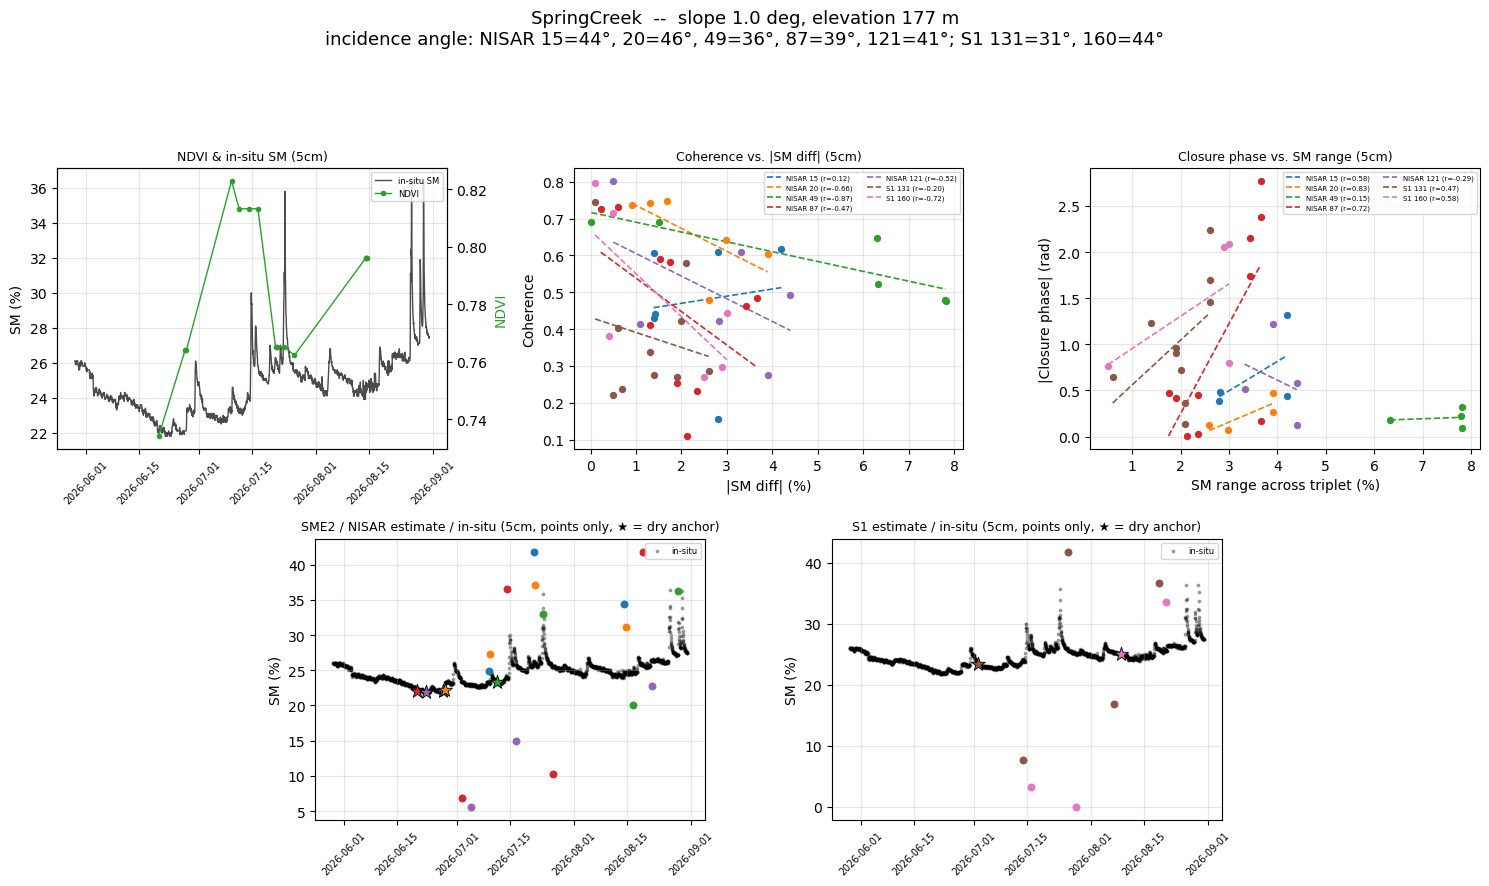

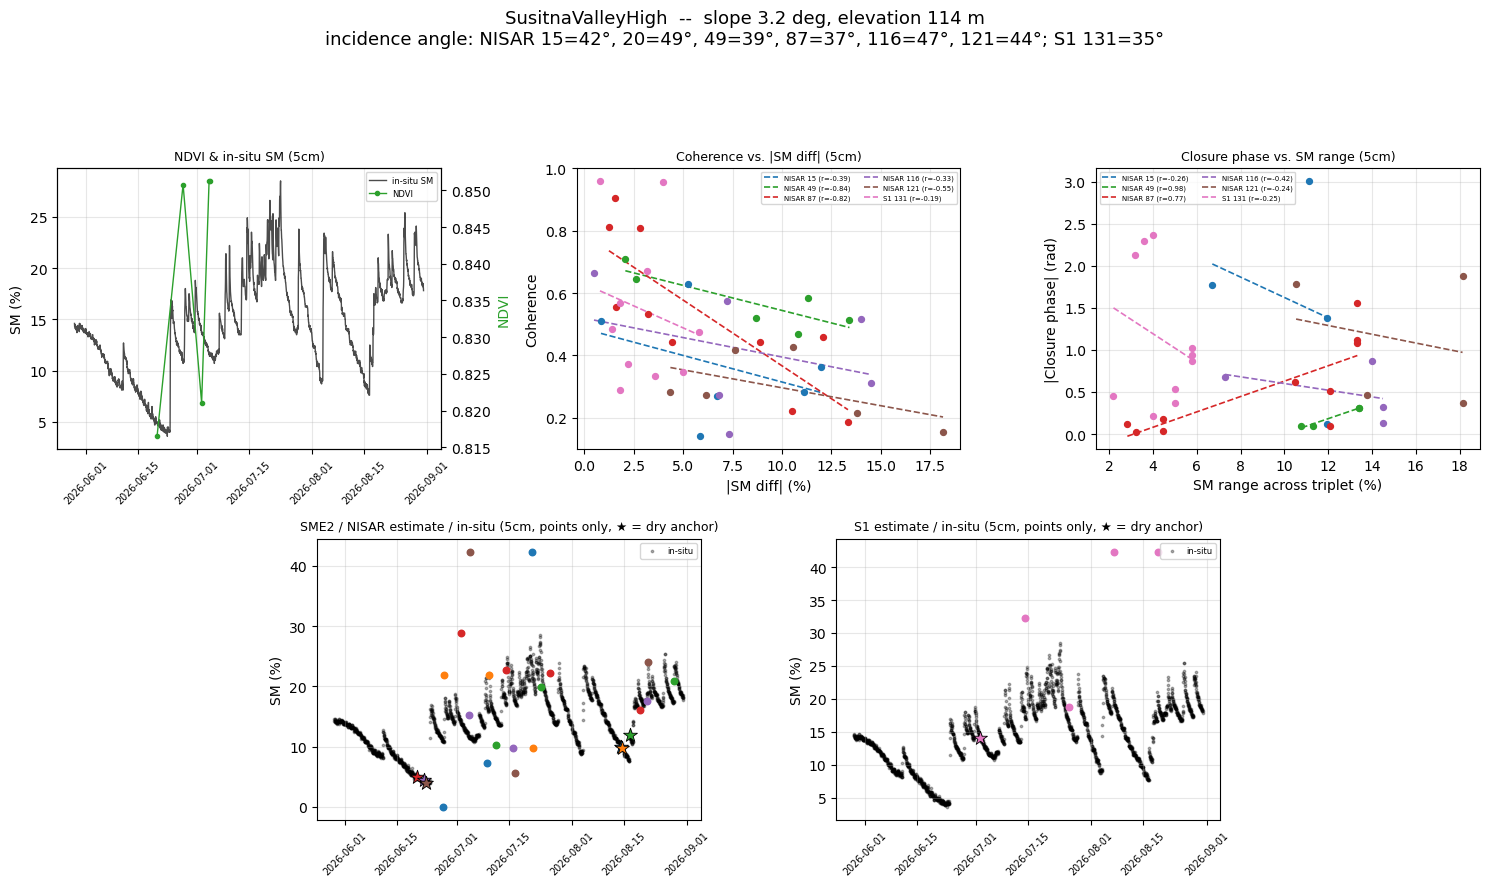

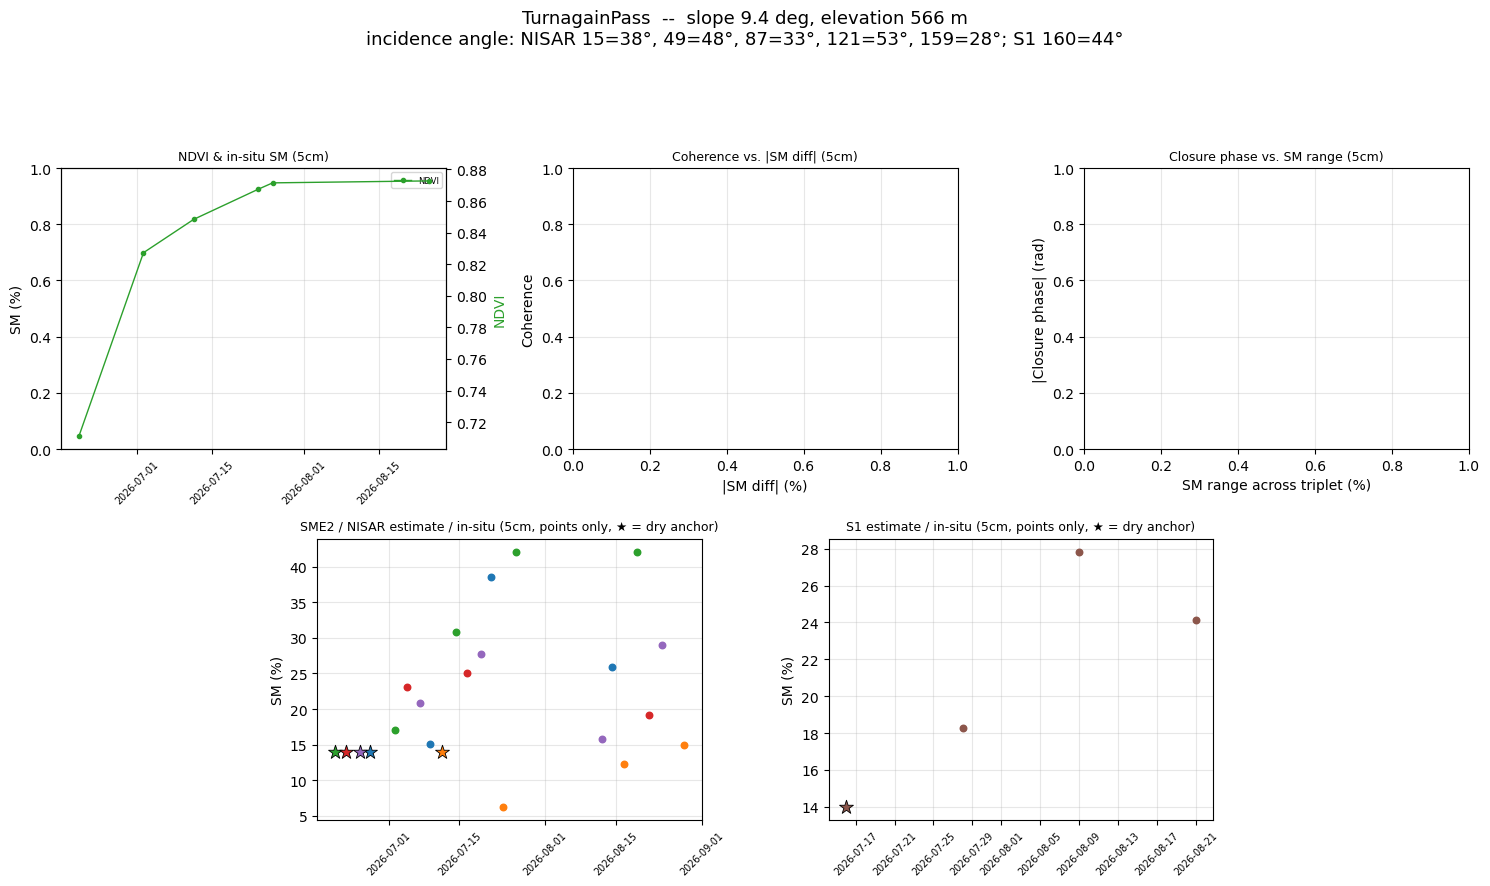

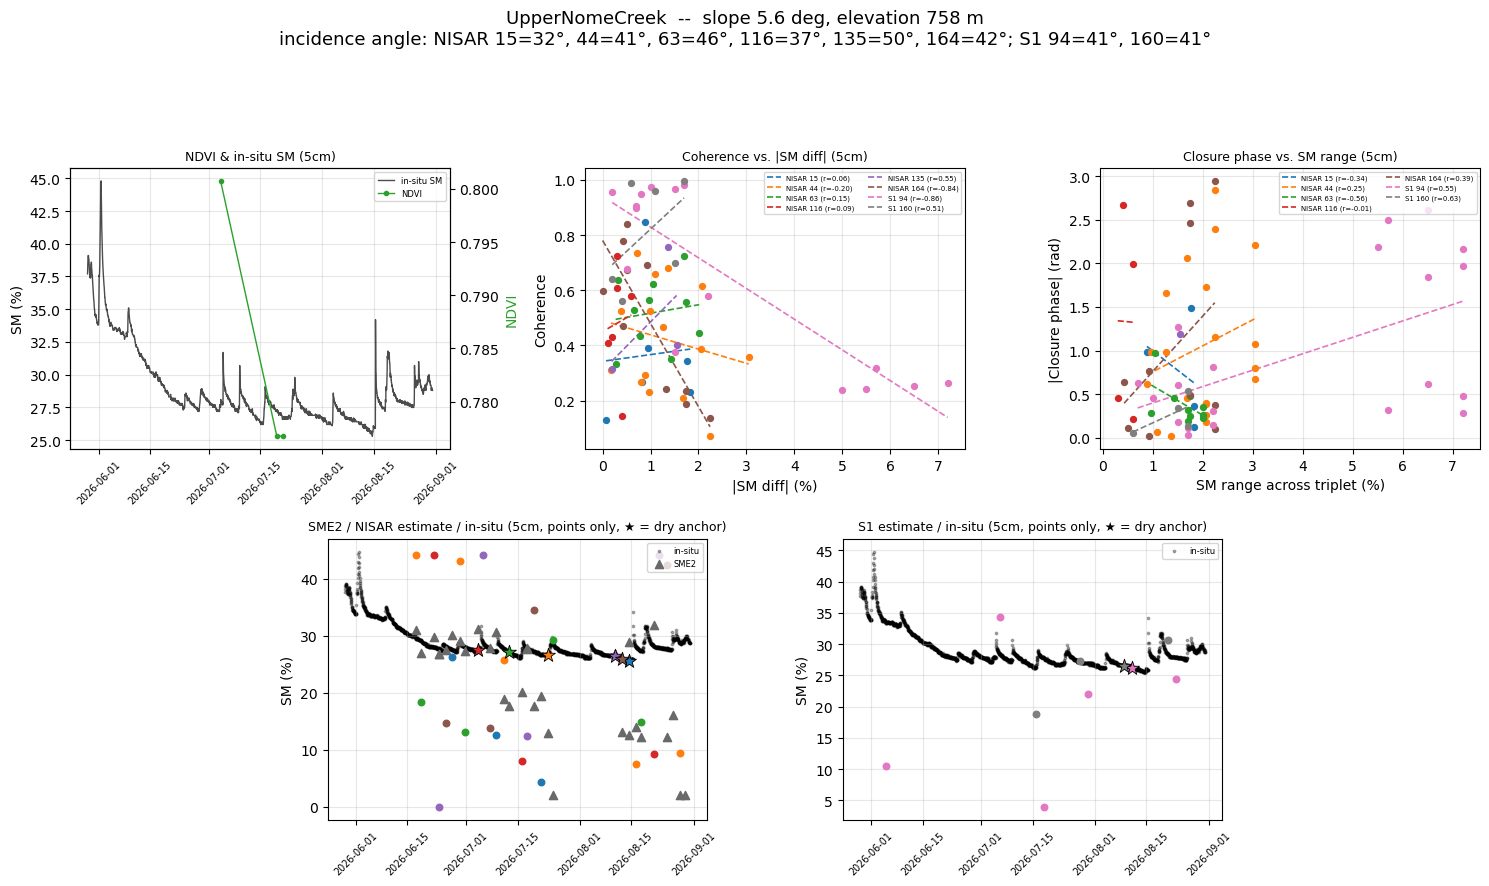

In [13]:
require_globals("stations_to_plot", "slope_by_station", "elevation_by_station")

import matplotlib.gridspec as gridspec

for station in stations_to_plot:
    nisar_tracks = set()
    coh = read_nisar_coherence(station)
    if coh is not None:
        nisar_tracks |= set(coh["orbit_num"].unique())
    s1_orbits = set()
    s1coh = read_s1_coherence(station)
    if s1coh is not None:
        s1_orbits |= set(s1coh["orbit"].unique())
    color_map = build_station_color_map(nisar_tracks, s1_orbits)

    fig = plt.figure(figsize=(15, 9))
    gs = gridspec.GridSpec(2, 6, figure=fig)
    series = read_insitu(station)
    has_ndvi = read_ndvi(station) is not None

    # Row 1: 3 panels fill the row (0:2, 2:4, 4:6); 2 panels are centered (1:3, 3:5).
    if has_ndvi:
        ax_ndvi = fig.add_subplot(gs[0, 0:2])
        ax_coh = fig.add_subplot(gs[0, 2:4])
        ax_clo = fig.add_subplot(gs[0, 4:6])
        plot_ndvi_insitu(ax_ndvi, station)
    else:
        ax_coh = fig.add_subplot(gs[0, 1:3])
        ax_clo = fig.add_subplot(gs[0, 3:5])
    plot_coherence_merged(ax_coh, station, series, color_map)
    plot_closure_merged(ax_clo, station, series, color_map)

    # Row 2: always 2 panels, always centered (1:3, 3:5).
    ax_nisar_ts = fig.add_subplot(gs[1, 1:3])
    ax_s1_ts = fig.add_subplot(gs[1, 3:5])
    plot_nisar_estimate_timeseries(ax_nisar_ts, station, color_map)
    plot_s1_estimate_timeseries(ax_s1_ts, station, color_map)

    slope = slope_by_station.get(station, np.nan)
    elev = elevation_by_station.get(station, np.nan)
    slope_str = f"{slope:.1f} deg" if not np.isnan(slope) else "n/a"
    elev_str = f"{elev:.0f} m" if not np.isnan(elev) else "n/a"
    inc_text = incidence_summary_text(station)
    title = f"{station}  --  slope {slope_str}, elevation {elev_str}"
    if inc_text:
        title += f"\n{inc_text}"
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()


## Summary

One page per station in `stations_to_plot` (stations with no NISAR/S1 5cm
estimate at all are skipped -- see Section 5's printed list). Every panel
auto-scales to that station's own data; colors are consistent only within
one station's own set of panels (`build_station_color_map`, Section 6), not
across stations. Coherence and closure-phase panels pool NISAR and
Sentinel-1 onto one axes each, legend-labeled `<satellite> <track>`. Local
incidence angle (per track, both sensors) and terrain slope/elevation are
printed in the page title rather than given their own panels. Re-run
`NISAR_SM_alaska.ipynb` / `S1_SM_alaska.ipynb` first (their Section 12
export cell) if you want the estimate-timeseries panels to reflect a fresh
inversion run.